# Projet 10 : Produisez une étude de marché avec Python

## Partie 2 : Analyse des données - Premier tri des pays

### 2-1 Import des données nettoyées et préparées

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

import seaborn as sns

import os
os.environ["OMP_NUM_THREADS"] = '1'

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [2]:
sns.set()

In [3]:
#Importation du fichier poulet_final.csv
poulet_final = pd.read_csv("C:/Users/capel/Desktop/Data Analyst/Projet 10/poulet_final.csv")


In [4]:
poulet_final.head()

,Country,Produit,Year,Domestic supply,Exportations,Importations,Production,Population,Region,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,Infrastructures,GES per capita,Renewable energy consumption,Tariffs
0,Armenia,Viande de Volailles,2017,47.0,0.000000,35.0,11.0,2.94,ECA,35.0,-0.30,51.13,7.50,0.97,3869.0,2.48,3.00,12.6,0.80
1,Afghanistan,Viande de Volailles,2017,57.0,99.136364,29.0,28.0,36.30,AP,15.0,-2.61,23.30,2.65,4.98,525.0,1.81,0.85,19.5,0.05
2,Albania,Viande de Volailles,2017,47.0,0.000000,38.0,13.0,2.88,ECA,38.0,0.16,56.32,3.28,1.99,5006.0,2.29,3.47,36.9,0.10
3,Algeria,Viande de Volailles,2017,277.0,0.000000,2.0,275.0,41.39,MENA,33.0,-0.93,41.17,1.50,5.59,4555.0,2.42,5.56,0.1,0.30
4,Angola,Viande de Volailles,2017,319.0,0.000000,277.0,42.0,29.82,SSA,19.0,-0.54,32.52,-0.16,29.84,2832.0,1.86,2.49,52.5,0.10


In [5]:
poulet_final.shape

(169, 19)

In [6]:
poulet_final.columns

Index(['Country', 'Produit', 'Year', 'Domestic supply', 'Exportations',
       'Importations', 'Production', 'Population', 'Region', 'CPI Score',
       'Political Stability', 'Government Effectiveness', 'Growth',
       'Inflation', 'GDP per capita', 'Infrastructures', 'GES per capita',
       'Renewable energy consumption', 'Tariffs'],
      dtype='object')

In [7]:
poulet_final.isna().sum()

Country                         0
Produit                         0
Year                            0
Domestic supply                 0
Exportations                    0
Importations                    0
Production                      0
Population                      0
Region                          0
CPI Score                       0
Political Stability             0
Government Effectiveness        0
Growth                          0
Inflation                       0
GDP per capita                  0
Infrastructures                 0
GES per capita                  0
Renewable energy consumption    0
Tariffs                         0
dtype: int64

In [8]:
poulet_final.dtypes

Country                          object
Produit                          object
Year                              int64
Domestic supply                 float64
Exportations                    float64
Importations                    float64
Production                      float64
Population                      float64
Region                           object
CPI Score                       float64
Political Stability             float64
Government Effectiveness        float64
Growth                          float64
Inflation                       float64
GDP per capita                  float64
Infrastructures                 float64
GES per capita                  float64
Renewable energy consumption    float64
Tariffs                         float64
dtype: object

In [9]:
poulet_final.shape

(169, 19)

In [10]:
poulet_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169 entries, 0 to 168
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Country                       169 non-null    object 
 1   Produit                       169 non-null    object 
 2   Year                          169 non-null    int64  
 3   Domestic supply               169 non-null    float64
 4   Exportations                  169 non-null    float64
 5   Importations                  169 non-null    float64
 6   Production                    169 non-null    float64
 7   Population                    169 non-null    float64
 8   Region                        169 non-null    object 
 9   CPI Score                     169 non-null    float64
 10  Political Stability           169 non-null    float64
 11  Government Effectiveness      169 non-null    float64
 12  Growth                        169 non-null    float64
 13  Infla

In [11]:
countries = poulet_final['Country']
countries
region = poulet_final['Region']

In [12]:
poulet_final.describe()

,Year,Domestic supply,Exportations,Importations,Production,Population,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,Infrastructures,GES per capita,Renewable energy consumption,Tariffs
count,169.0,169.00000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000
mean,2017.0,682.35503,119.907180,87.065089,718.365127,42.988225,43.680980,-0.080438,52.390093,3.438810,4.039347,13353.194772,2.687024,6.528778,32.845046,0.235653
std,0.0,2192.61443,460.757779,184.430370,2493.551107,154.387785,16.886609,0.792927,15.967935,2.716604,4.611912,17900.377068,0.569531,6.057436,25.813704,0.274508
min,2017.0,2.00000,0.000000,0.000000,0.000000,0.050000,15.000000,-2.610000,14.580000,-7.540000,-1.540000,432.000000,1.560000,0.580000,0.000000,0.000000
25%,2017.0,30.00000,0.000000,3.000000,14.000000,2.850000,32.000000,-0.551714,41.660000,2.175000,1.600000,2179.972973,2.257333,2.250000,12.600000,0.020500
50%,2017.0,98.00000,3.166667,16.000000,71.000000,9.730000,40.904762,-0.110000,50.553600,3.530000,2.934000,6521.533333,2.563333,5.560000,27.600000,0.157215
75%,2017.0,357.00000,63.937500,79.000000,392.000000,29.400000,51.000000,0.600000,58.880000,4.798846,4.660000,15695.000000,2.900000,8.490000,45.600000,0.350000
max,2017.0,18266.00000,4223.000000,1069.000000,21914.000000,1421.020000,89.000000,1.490000,92.370000,12.970000,32.350000,110193.000000,4.370000,35.310000,93.600000,1.840000


In [13]:
cols = [
    "Production",
    "Importations",
    "Exportations",
    "Domestic supply",
    "Population",
    "CPI Score",
    "Political Stability",
    "Government Effectiveness",
    "Growth",
    "Inflation",
    "GDP per capita",
    "GES per capita",
    "Renewable energy consumption",
    "Infrastructures",
    "Tariffs"
]

In [14]:
print([repr(col) for col in poulet_final.columns])

["'Country'", "'Produit'", "'Year'", "'Domestic supply'", "'Exportations'", "'Importations'", "'Production'", "'Population'", "'Region'", "'CPI Score'", "'Political Stability'", "'Government Effectiveness'", "'Growth'", "'Inflation'", "'GDP per capita'", "'Infrastructures'", "'GES per capita'", "'Renewable energy consumption'", "'Tariffs'"]


In [15]:
poulet_exp = poulet_final[cols]
poulet_exp.head()

,Production,Importations,Exportations,Domestic supply,Population,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,GES per capita,Renewable energy consumption,Infrastructures,Tariffs
0,11.0,35.0,0.000000,47.0,2.94,35.0,-0.30,51.13,7.50,0.97,3869.0,3.00,12.6,2.48,0.80
1,28.0,29.0,99.136364,57.0,36.30,15.0,-2.61,23.30,2.65,4.98,525.0,0.85,19.5,1.81,0.05
2,13.0,38.0,0.000000,47.0,2.88,38.0,0.16,56.32,3.28,1.99,5006.0,3.47,36.9,2.29,0.10
3,275.0,2.0,0.000000,277.0,41.39,33.0,-0.93,41.17,1.50,5.59,4555.0,5.56,0.1,2.42,0.30
4,42.0,277.0,0.000000,319.0,29.82,19.0,-0.54,32.52,-0.16,29.84,2832.0,2.49,52.5,1.86,0.10


In [16]:
poulet_exp.shape

(169, 15)

## 2-2 : Réalisation de l'ACP

In [17]:
X = poulet_exp.values
X[:5]

array([[ 1.10000000e+01,  3.50000000e+01,  0.00000000e+00,
         4.70000000e+01,  2.94000000e+00,  3.50000000e+01,
        -3.00000000e-01,  5.11300000e+01,  7.50000000e+00,
         9.70000000e-01,  3.86900000e+03,  3.00000000e+00,
         1.26000000e+01,  2.48000000e+00,  8.00000000e-01],
       [ 2.80000000e+01,  2.90000000e+01,  9.91363636e+01,
         5.70000000e+01,  3.63000000e+01,  1.50000000e+01,
        -2.61000000e+00,  2.33000000e+01,  2.65000000e+00,
         4.98000000e+00,  5.25000000e+02,  8.50000000e-01,
         1.95000000e+01,  1.81000000e+00,  5.00000000e-02],
       [ 1.30000000e+01,  3.80000000e+01,  0.00000000e+00,
         4.70000000e+01,  2.88000000e+00,  3.80000000e+01,
         1.60000000e-01,  5.63200000e+01,  3.28000000e+00,
         1.99000000e+00,  5.00600000e+03,  3.47000000e+00,
         3.69000000e+01,  2.29000000e+00,  1.00000000e-01],
       [ 2.75000000e+02,  2.00000000e+00,  0.00000000e+00,
         2.77000000e+02,  4.13900000e+01,  3.30000000

In [18]:
type(X)

numpy.ndarray

In [19]:
X.shape

(169, 15)

In [20]:
indicators = poulet_exp.columns
indicators

Index(['Production', 'Importations', 'Exportations', 'Domestic supply',
       'Population', 'CPI Score', 'Political Stability',
       'Government Effectiveness', 'Growth', 'Inflation', 'GDP per capita',
       'GES per capita', 'Renewable energy consumption', 'Infrastructures',
       'Tariffs'],
      dtype='object')

#### Standardisation des données ####

In [21]:
scaler = StandardScaler()

In [22]:
scaler.fit(X)

,copy,True
,with_mean,True
,with_std,True


In [23]:
X_scaled = scaler.transform(X)
X_scaled[:5]

array([[-0.28452084, -0.28314108, -0.26101245, -0.29063166, -0.2601711 ,
        -0.51560251, -0.27772395, -0.0791485 ,  1.49939376, -0.6675038 ,
        -0.53140666, -0.58428437, -0.78660582, -0.3645801 ,  2.06195933],
       [-0.27768299, -0.31577037, -0.04521365, -0.28605734, -0.04344969,
        -1.70349261, -3.19963873, -1.82719575, -0.29122904,  0.20456769,
        -0.71877353, -0.94027481, -0.51851159, -1.54448311, -0.67831959],
       [-0.28371639, -0.26682644, -0.26101245, -0.29063166, -0.26056088,
        -0.337419  ,  0.30412921,  0.24684378, -0.05863268, -0.44568013,
        -0.46769969, -0.5064632 ,  0.15755213, -0.69917946, -0.49563433],
       [-0.1783331 , -0.46260214, -0.26101245, -0.18542232, -0.01038278,
        -0.63439152, -1.0746098 , -0.70475219, -0.7158097 ,  0.33722694,
        -0.49296956, -0.16040738, -1.27228378, -0.47024305,  0.23510672],
       [-0.27205183,  1.03290665, -0.26101245, -0.16621018, -0.08554665,
        -1.46591459, -0.58129951, -1.24807266, 

In [24]:
idx = ["mean", "std"]

pd.DataFrame(X_scaled).describe().round(2).loc[idx, :]

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
mean,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


#### Eboulis des valeurs propres #### 

In [25]:
n_components = 8
pca = PCA(n_components=n_components)

In [26]:
X_pca = pca.fit_transform(X_scaled)

In [27]:
pca.explained_variance_ratio_

array([0.32615154, 0.20370879, 0.08754789, 0.06861438, 0.0656762 ,
       0.06086208, 0.04826833, 0.0414036 ])

In [28]:
scree = (pca.explained_variance_ratio_*100).round(2)
scree

array([32.62, 20.37,  8.75,  6.86,  6.57,  6.09,  4.83,  4.14])

In [29]:
scree_cum = scree.cumsum().round()
scree_cum

array([33., 53., 62., 69., 75., 81., 86., 90.])

In [30]:
x_list = range(1, n_components+1)
list(x_list)

[1, 2, 3, 4, 5, 6, 7, 8]

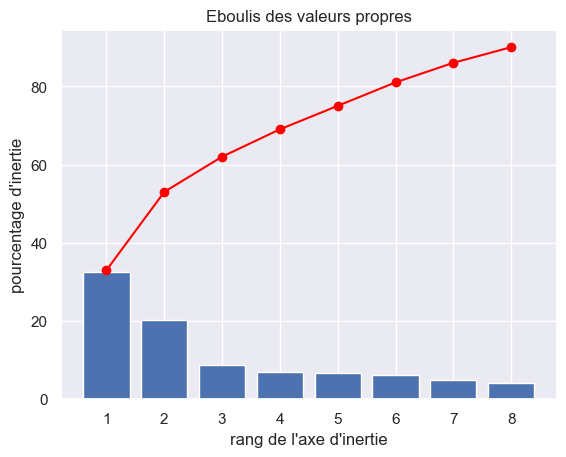

In [31]:
plt.bar(x_list, scree)
plt.plot(x_list, scree_cum,c="red",marker='o')
plt.xlabel("rang de l'axe d'inertie")
plt.ylabel("pourcentage d'inertie")
plt.title("Eboulis des valeurs propres")
plt.show(block=False)

Les deux premiers axes expliquent **52,6 % de l'inertie totale**. 

In [32]:
pca

,n_components,8
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [33]:
pcs = pca.components_
pcs

array([[ 0.10904409,  0.17063636,  0.10423209,  0.11237117,  0.04303113,
         0.3926117 ,  0.33147679,  0.41149915, -0.06668223, -0.20882451,
         0.37567038,  0.28765603, -0.23714145,  0.40435083, -0.09291337],
       [ 0.54094517,  0.12857724,  0.41129019,  0.53916584,  0.40735247,
        -0.08663634, -0.16002886, -0.09170897,  0.03479898,  0.03654801,
        -0.13169054, -0.05642717, -0.0042436 , -0.01025855, -0.01813116],
       [ 0.03722153, -0.31880864,  0.02063445,  0.01131744,  0.11374429,
         0.21065593,  0.20430175,  0.15964575,  0.65114152, -0.15363027,
         0.08577969, -0.40385591,  0.38640611,  0.04350126,  0.0513299 ],
       [-0.06346948,  0.22612411, -0.3831116 ,  0.02648785,  0.34545954,
        -0.09551034, -0.13190585,  0.10471412,  0.23708276, -0.04919914,
         0.01215548,  0.08005531, -0.24795371,  0.0351763 ,  0.71598246],
       [ 0.08605063, -0.17667192,  0.20993482,  0.04449959, -0.15370283,
         0.22316351,  0.08655541,  0.0994283 , 

In [34]:
pcs = pd.DataFrame(pcs)
pcs

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,0.109044,0.170636,0.104232,0.112371,0.043031,0.392612,0.331477,0.411499,-0.066682,-0.208825,0.375670,0.287656,-0.237141,0.404351,-0.092913
1,0.540945,0.128577,0.411290,0.539166,0.407352,-0.086636,-0.160029,-0.091709,0.034799,0.036548,-0.131691,-0.056427,-0.004244,-0.010259,-0.018131
2,0.037222,-0.318809,0.020634,0.011317,0.113744,0.210656,0.204302,0.159646,0.651142,-0.153630,0.085780,-0.403856,0.386406,0.043501,0.051330
3,-0.063469,0.226124,-0.383112,0.026488,0.345460,-0.095510,-0.131906,0.104714,0.237083,-0.049199,0.012155,0.080055,-0.247954,0.035176,0.715982
4,0.086051,-0.176672,0.209935,0.044500,-0.153703,0.223164,0.086555,0.099428,-0.358230,0.505663,0.204581,-0.044854,0.314073,-0.034309,0.544809
5,-0.115543,0.568078,-0.204130,-0.046709,0.179885,0.023937,-0.142423,0.071887,0.124271,0.504625,0.138893,-0.087156,0.357386,0.212222,-0.303254
6,-0.015312,0.608496,0.356106,-0.047032,-0.509308,0.024834,-0.021232,-0.058862,0.117184,-0.303299,-0.053339,-0.248938,0.063411,-0.041029,0.245573
7,0.032185,-0.033848,0.213960,-0.016590,-0.265451,-0.065422,0.158589,0.065560,0.520952,0.547249,-0.076887,0.187139,-0.466851,-0.126584,-0.042350


In [35]:
pcs.columns = indicators
pcs.index = [f"F{i}" for i in x_list]
pcs.round(2)

,Production,Importations,Exportations,Domestic supply,Population,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,GES per capita,Renewable energy consumption,Infrastructures,Tariffs
F1,0.11,0.17,0.10,0.11,0.04,0.39,0.33,0.41,-0.07,-0.21,0.38,0.29,-0.24,0.40,-0.09
F2,0.54,0.13,0.41,0.54,0.41,-0.09,-0.16,-0.09,0.03,0.04,-0.13,-0.06,-0.00,-0.01,-0.02
F3,0.04,-0.32,0.02,0.01,0.11,0.21,0.20,0.16,0.65,-0.15,0.09,-0.40,0.39,0.04,0.05
F4,-0.06,0.23,-0.38,0.03,0.35,-0.10,-0.13,0.10,0.24,-0.05,0.01,0.08,-0.25,0.04,0.72
F5,0.09,-0.18,0.21,0.04,-0.15,0.22,0.09,0.10,-0.36,0.51,0.20,-0.04,0.31,-0.03,0.54
F6,-0.12,0.57,-0.20,-0.05,0.18,0.02,-0.14,0.07,0.12,0.50,0.14,-0.09,0.36,0.21,-0.30
F7,-0.02,0.61,0.36,-0.05,-0.51,0.02,-0.02,-0.06,0.12,-0.30,-0.05,-0.25,0.06,-0.04,0.25
F8,0.03,-0.03,0.21,-0.02,-0.27,-0.07,0.16,0.07,0.52,0.55,-0.08,0.19,-0.47,-0.13,-0.04


In [36]:
pcs.T

,F1,F2,F3,F4,F5,F6,F7,F8
Production,0.109044,0.540945,0.037222,-0.063469,0.086051,-0.115543,-0.015312,0.032185
Importations,0.170636,0.128577,-0.318809,0.226124,-0.176672,0.568078,0.608496,-0.033848
Exportations,0.104232,0.411290,0.020634,-0.383112,0.209935,-0.204130,0.356106,0.213960
Domestic supply,0.112371,0.539166,0.011317,0.026488,0.044500,-0.046709,-0.047032,-0.016590
Population,0.043031,0.407352,0.113744,0.345460,-0.153703,0.179885,-0.509308,-0.265451
CPI Score,0.392612,-0.086636,0.210656,-0.095510,0.223164,0.023937,0.024834,-0.065422
Political Stability,0.331477,-0.160029,0.204302,-0.131906,0.086555,-0.142423,-0.021232,0.158589
Government Effectiveness,0.411499,-0.091709,0.159646,0.104714,0.099428,0.071887,-0.058862,0.065560
Growth,-0.066682,0.034799,0.651142,0.237083,-0.358230,0.124271,0.117184,0.520952
Inflation,-0.208825,0.036548,-0.153630,-0.049199,0.505663,0.504625,-0.303299,0.547249


<Axes: >

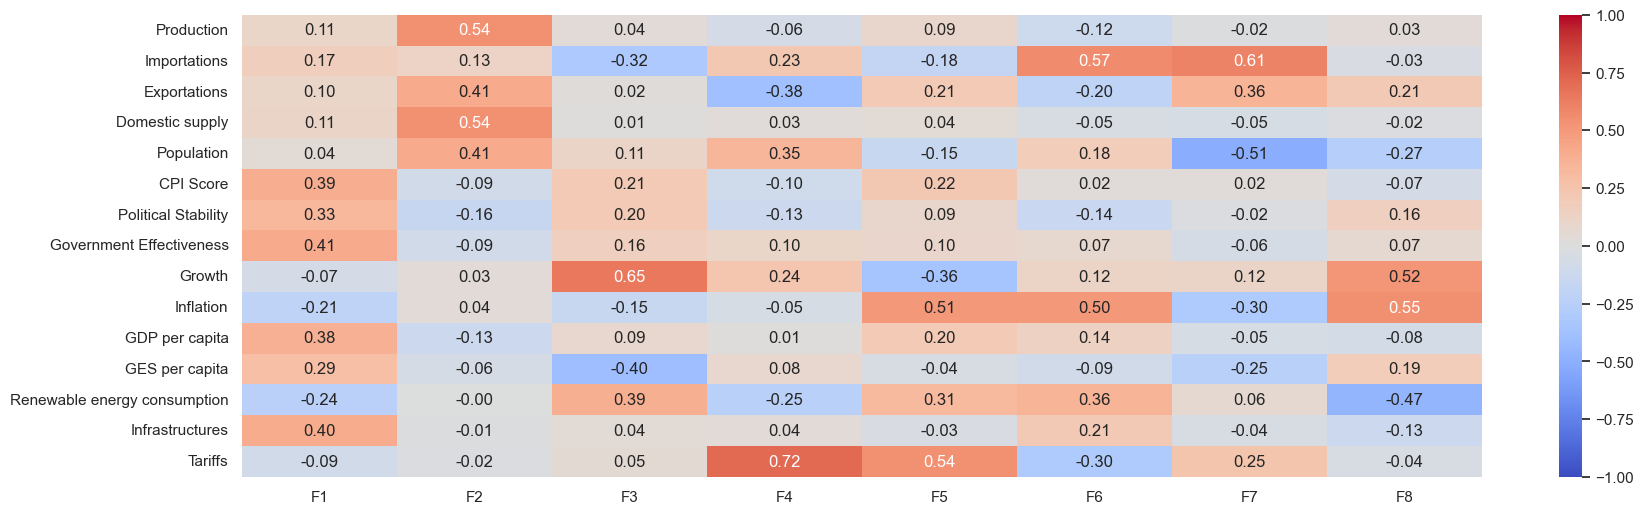

In [37]:
fig, ax = plt.subplots(figsize=(20, 6))
sns.heatmap(pcs.T, vmin=-1, vmax=1, annot=True, cmap="coolwarm", fmt="0.2f")

**F1 élevé** => dimension de développement économique et institutionnel

**F2 élevé** => taille du marché de poulets et son volume d'activité

**F3 élevé** => dynamique de croissance et énergies renouvelables

**F4 élevé** => droits de douane

**F5 élevé** => inflation et transition énergétique

**F6 élevé** => importations et inflation

**F7 élevé** => importations et population

**F8 élevé** => croissance, inflation et énergies renouvelables

### Cercle des corrélations ###

In [38]:
x, y = 0,1

In [39]:
def correlation_graph(pca, 
                      x_y, 
                      features) : 
    """Affiche le graphe des correlations

    Positional arguments : 
    -----------------------------------
    pca : sklearn.decomposition.PCA : notre objet PCA qui a été fit
    x_y : list ou tuple : le couple x,y des plans à afficher, exemple [0,1] pour F1, F2
    features : list ou tuple : la liste des features (ie des dimensions) à représenter
    """

    # Extrait x et y 
    x,y=x_y

    # Taille de l'image (en inches)
    fig, ax = plt.subplots(figsize=(10, 9))

    # Pour chaque composante : 
    for i in range(0, pca.components_.shape[1]):

        # Les flèches
        ax.arrow(0,0, 
                pca.components_[x, i],  
                pca.components_[y, i],  
                head_width=0.07,
                head_length=0.07, 
                width=0.02, )

        # Les labels
        plt.text(pca.components_[x, i] + 0.05,
                pca.components_[y, i] + 0.05,
                features[i])
        
    # Affichage des lignes horizontales et verticales
    plt.plot([-1, 1], [0, 0], color='grey', ls='--')
    plt.plot([0, 0], [-1, 1], color='grey', ls='--')

    # Nom des axes, avec le pourcentage d'inertie expliqué
    plt.xlabel('F{} ({}%)'.format(x+1, round(100*pca.explained_variance_ratio_[x],1)))
    plt.ylabel('F{} ({}%)'.format(y+1, round(100*pca.explained_variance_ratio_[y],1)))

    plt.title("Cercle des corrélations (F{} et F{})".format(x+1, y+1))

    # Le cercle 
    an = np.linspace(0, 2 * np.pi, 100)
    plt.plot(np.cos(an), np.sin(an))  # Add a unit circle for scale

    # Axes et display
    plt.axis('equal')
    plt.show(block=False)

In [40]:
x_y = (0,1)

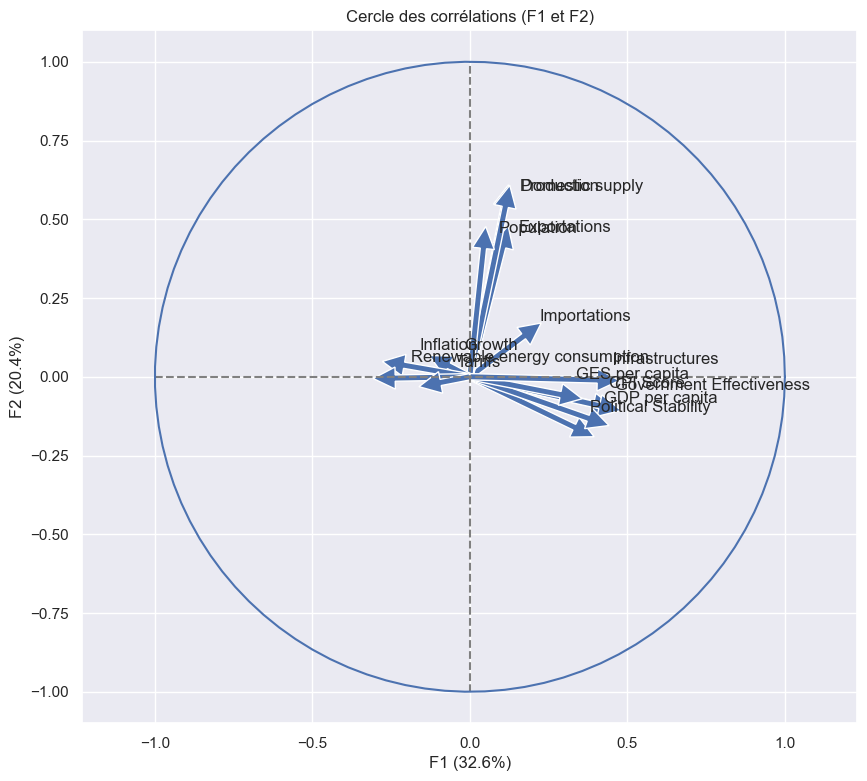

In [41]:
correlation_graph(pca, x_y, indicators)

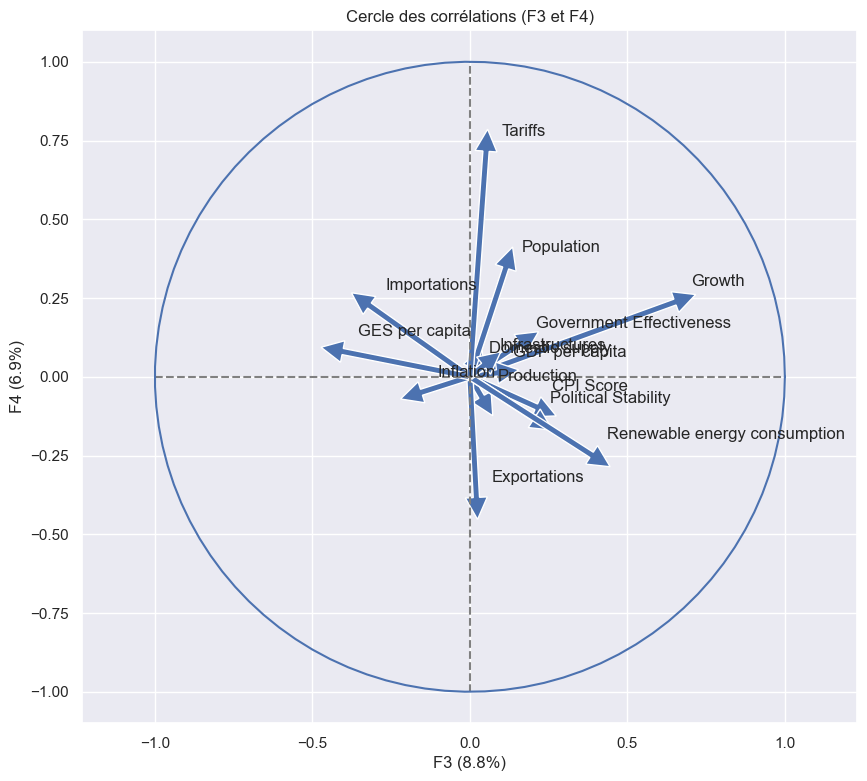

In [42]:
correlation_graph(pca, (2,3), indicators)

### Projection des individus ###

In [43]:
X_proj = pca.transform(X_scaled)
X_proj[:5]

array([[-0.95822303, -0.36355058,  0.91869984,  2.0276747 , -0.21750718,
        -1.24357771,  0.90643952,  0.67635386],
       [-3.60651924,  0.62124739, -1.42836549, -0.24017337, -1.19894662,
        -0.10717229,  0.0049213 , -0.20158069],
       [-0.57606577, -0.5127167 ,  0.2663901 , -0.47881406, -0.50326583,
        -0.32723686,  0.06233267, -0.19278934],
       [-1.20645653, -0.00859459, -1.32892869,  0.3888798 , -0.22180401,
        -0.6939743 , -0.43273891,  0.24784751],
       [-3.40567475,  0.38320162, -2.28461845, -0.84434867,  2.48593643,
         3.37871086, -1.03259629,  1.9952239 ]])

In [44]:
def display_factorial_planes(   X_projected, 
                                x_y, 
                                pca=None, 
                                labels= None,
                                clusters=None, 
                                alpha=1,
                                figsize=[20,16], 
                                s=100,
                                marker="o" ):
    """
    Affiche la projection des individus

    Positional arguments : 
    -------------------------------------
    X_projected : np.array, pd.DataFrame, list of list : la matrice des points projetés
    x_y : list ou tuple : le couple x,y des plans à afficher, exemple [0,1] pour F1, F2

    Optional arguments : 
    -------------------------------------
    pca : sklearn.decomposition.PCA : un objet PCA qui a été fit, cela nous permettra d'afficher la variance de chaque composante, default = None
    labels : list ou tuple : les labels des individus à projeter, default = None
    clusters : list ou tuple : la liste des clusters auquel appartient chaque individu, default = None
    alpha : float in [0,1] : paramètre de transparence, 0=100% transparent, 1=0% transparent, default = 1
    figsize : list ou tuple : couple width, height qui définit la taille de la figure en inches, default = [10,8] 
    marker : str : le type de marker utilisé pour représenter les individus, points croix etc etc, default = "."
    """

    # Transforme X_projected en np.array
    X_ = np.array(X_projected)

    # On définit la forme de la figure si elle n'a pas été donnée
    if not figsize: 
        figsize = (7,6)

    # On gère les labels
    if  labels is None : 
        labels = []
    try : 
        len(labels)
    except Exception as e : 
        raise e

    # On vérifie la variable axis 
    if not len(x_y) ==2 : 
        raise AttributeError("2 axes sont demandées")   
    if max(x_y )>= X_.shape[1] : 
        raise AttributeError("la variable axis n'est pas bonne")   

    # on définit x et y 
    x, y = x_y

    # Initialisation de la figure       
    fig, ax = plt.subplots(1, 1, figsize=figsize)

    # On vérifie s'il y a des clusters ou non
    c = None if clusters is None else clusters
 
    # Les points    
    # plt.scatter(   X_[:, x], X_[:, y], alpha=alpha, 
    #                     c=c, cmap="Set1", marker=marker)
    sns.scatterplot(data=None, x=X_[:, x], y=X_[:, y], hue=c)

    # Si la variable pca a été fournie, on peut calculer le % de variance de chaque axe 
    if pca : 
        v1 = str(round(100*pca.explained_variance_ratio_[x]))  + " %"
        v2 = str(round(100*pca.explained_variance_ratio_[y]))  + " %"
    else : 
        v1=v2= ''

    # Nom des axes, avec le pourcentage d'inertie expliqué
    ax.set_xlabel(f'F{x+1} {v1}')
    ax.set_ylabel(f'F{y+1} {v2}')

    # Valeur x max et y max
    x_max = np.abs(X_[:, x]).max() *1.1
    y_max = np.abs(X_[:, y]).max() *1.1

    # On borne x et y 
    ax.set_xlim(left=-x_max, right=x_max)
    ax.set_ylim(bottom= -y_max, top=y_max)

    # Affichage des lignes horizontales et verticales
    plt.plot([-x_max, x_max], [0, 0], color='grey', alpha=0.8)
    plt.plot([0,0], [-y_max, y_max], color='grey', alpha=0.8)

    # Affichage des labels des points
    if len(labels) : 
        for i,(_x,_y) in enumerate(X_[:,[x,y]]):
            plt.text(_x, _y+0.05, labels[i], fontsize='14', ha='center',va='center') 

    # Titre et display
    plt.title(f"Projection des individus (sur F{x+1} et F{y+1})")
    plt.show()

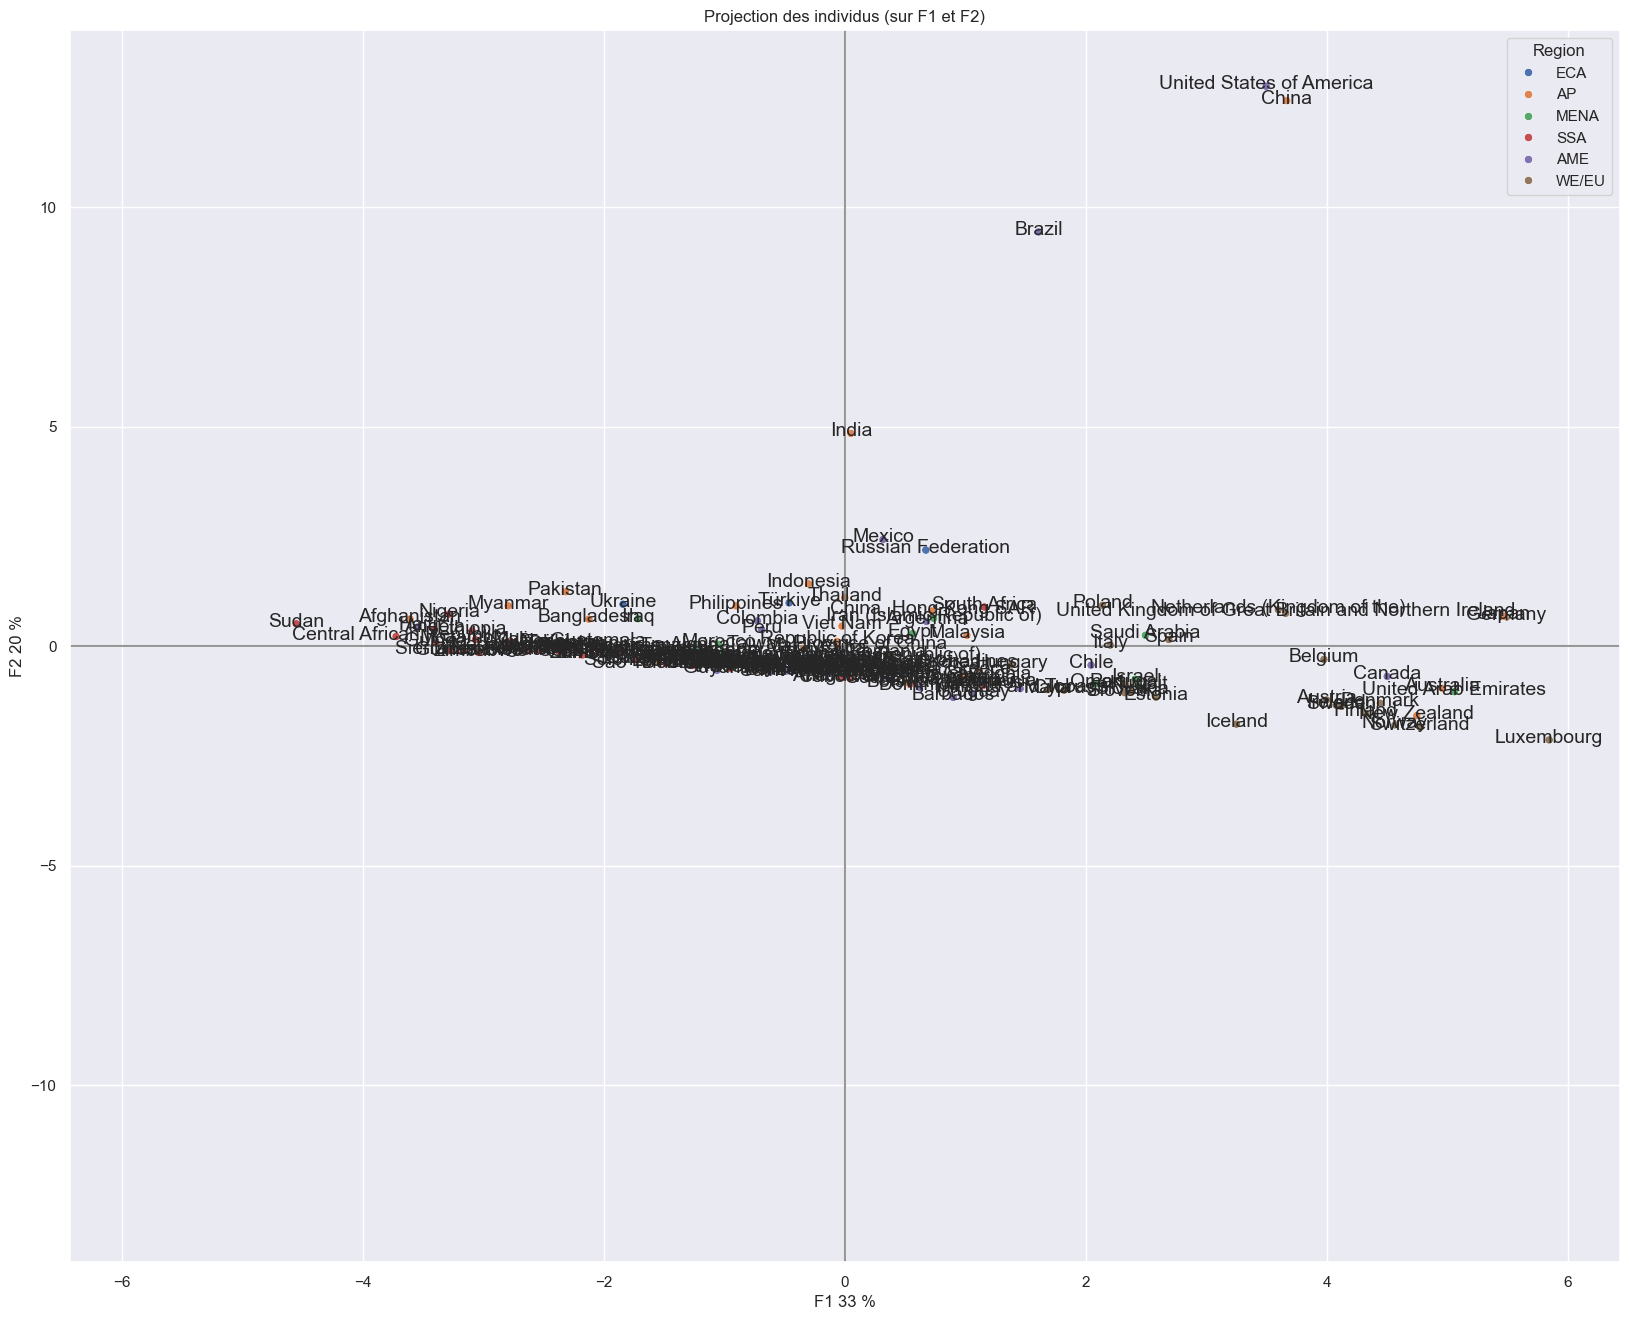

In [45]:
x_y = [0,1]
display_factorial_planes(X_proj, x_y, pca, labels=countries, figsize=(20,16), clusters=region, marker="o")

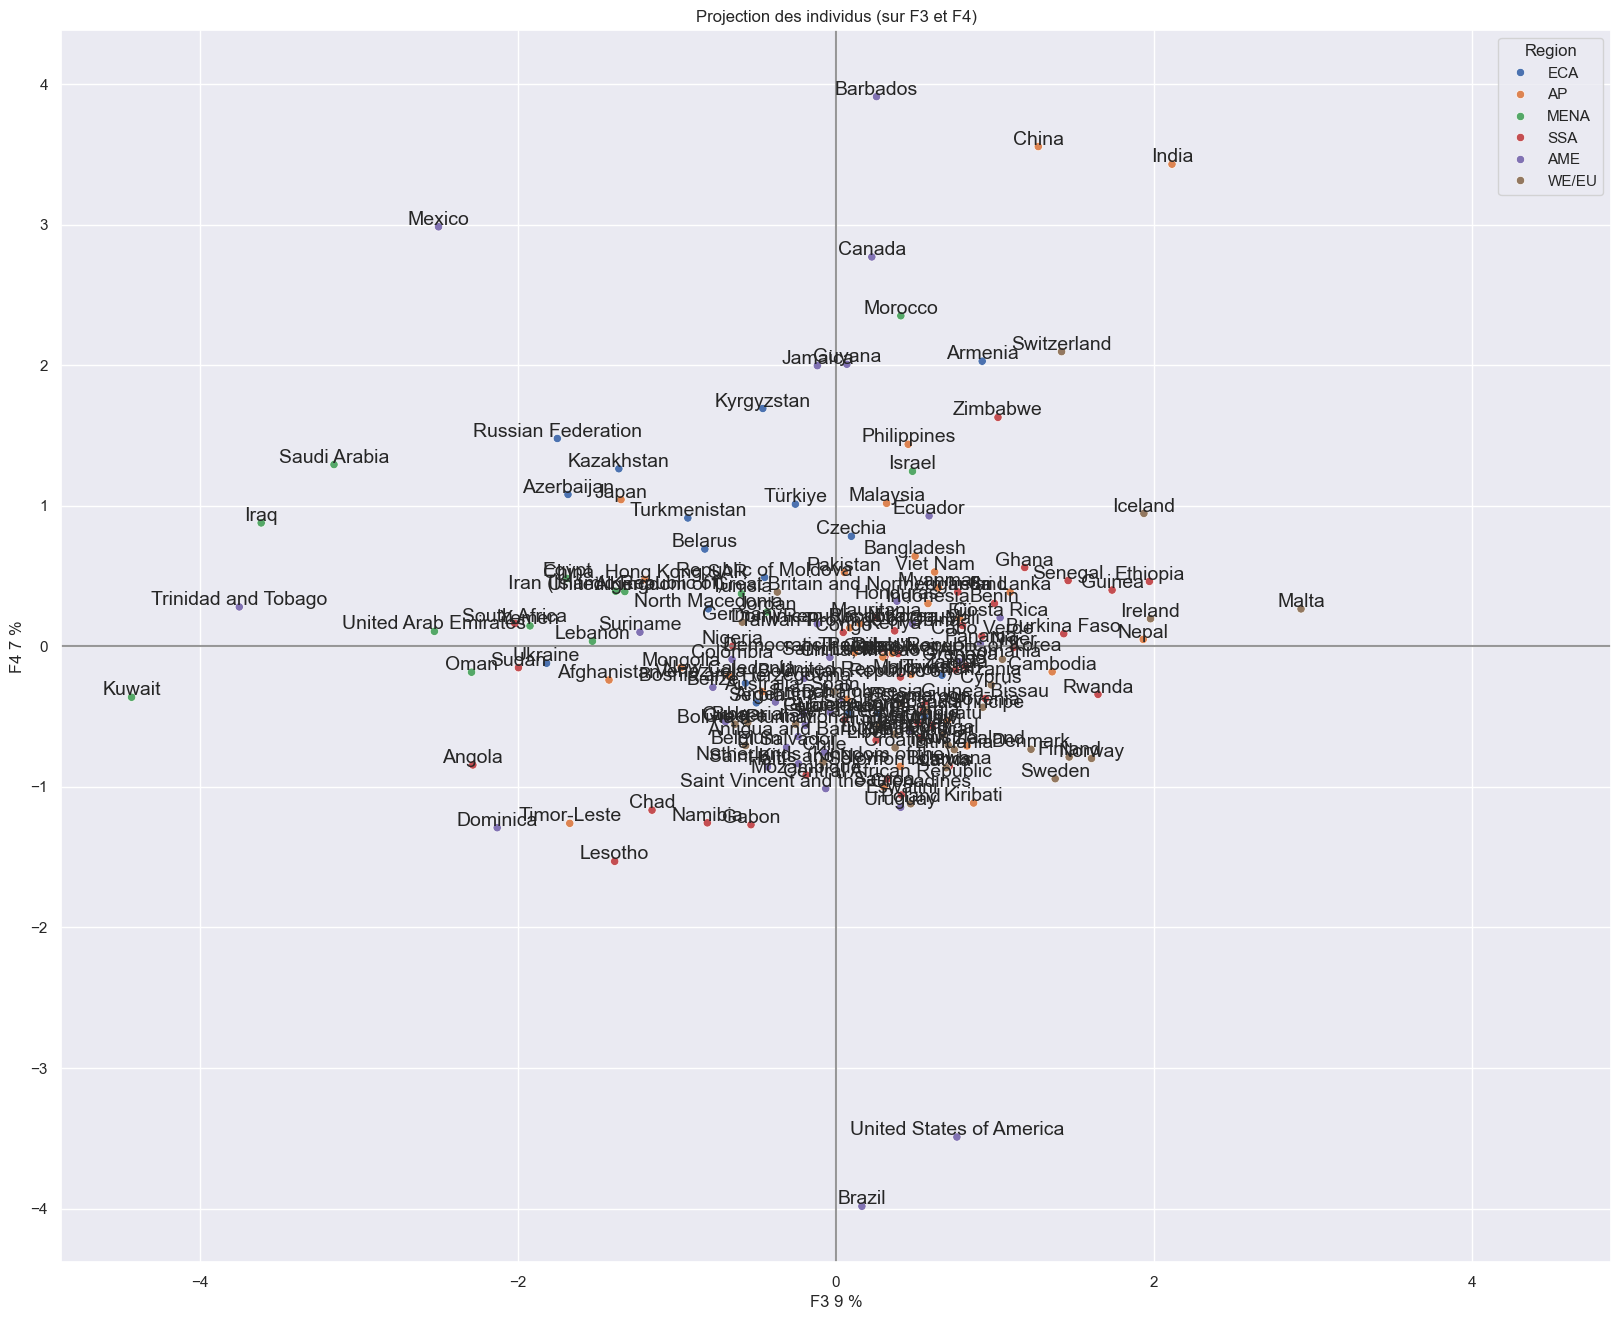

In [46]:
x_y = [2,3]
display_factorial_planes(X_proj, x_y, pca, labels=countries, figsize=(20,16), clusters=region, marker="o")

### Classification Ascendante Hiérarchique ###

#### Dendrogramme ####

In [47]:
Z = linkage(X_scaled, method="ward")
Z[:10]

array([[ 79.        ,  87.        ,   0.20494409,   2.        ],
       [ 80.        , 143.        ,   0.23537497,   2.        ],
       [ 48.        ,  71.        ,   0.27781323,   2.        ],
       [ 12.        , 158.        ,   0.41638544,   2.        ],
       [144.        , 171.        ,   0.50198565,   3.        ],
       [  9.        , 127.        ,   0.70150958,   2.        ],
       [126.        , 172.        ,   0.75659234,   3.        ],
       [166.        , 167.        ,   0.87213813,   2.        ],
       [ 62.        ,  82.        ,   0.90373917,   2.        ],
       [ 88.        ,  89.        ,   0.91122079,   2.        ]])

In [48]:
countries = countries.tolist()

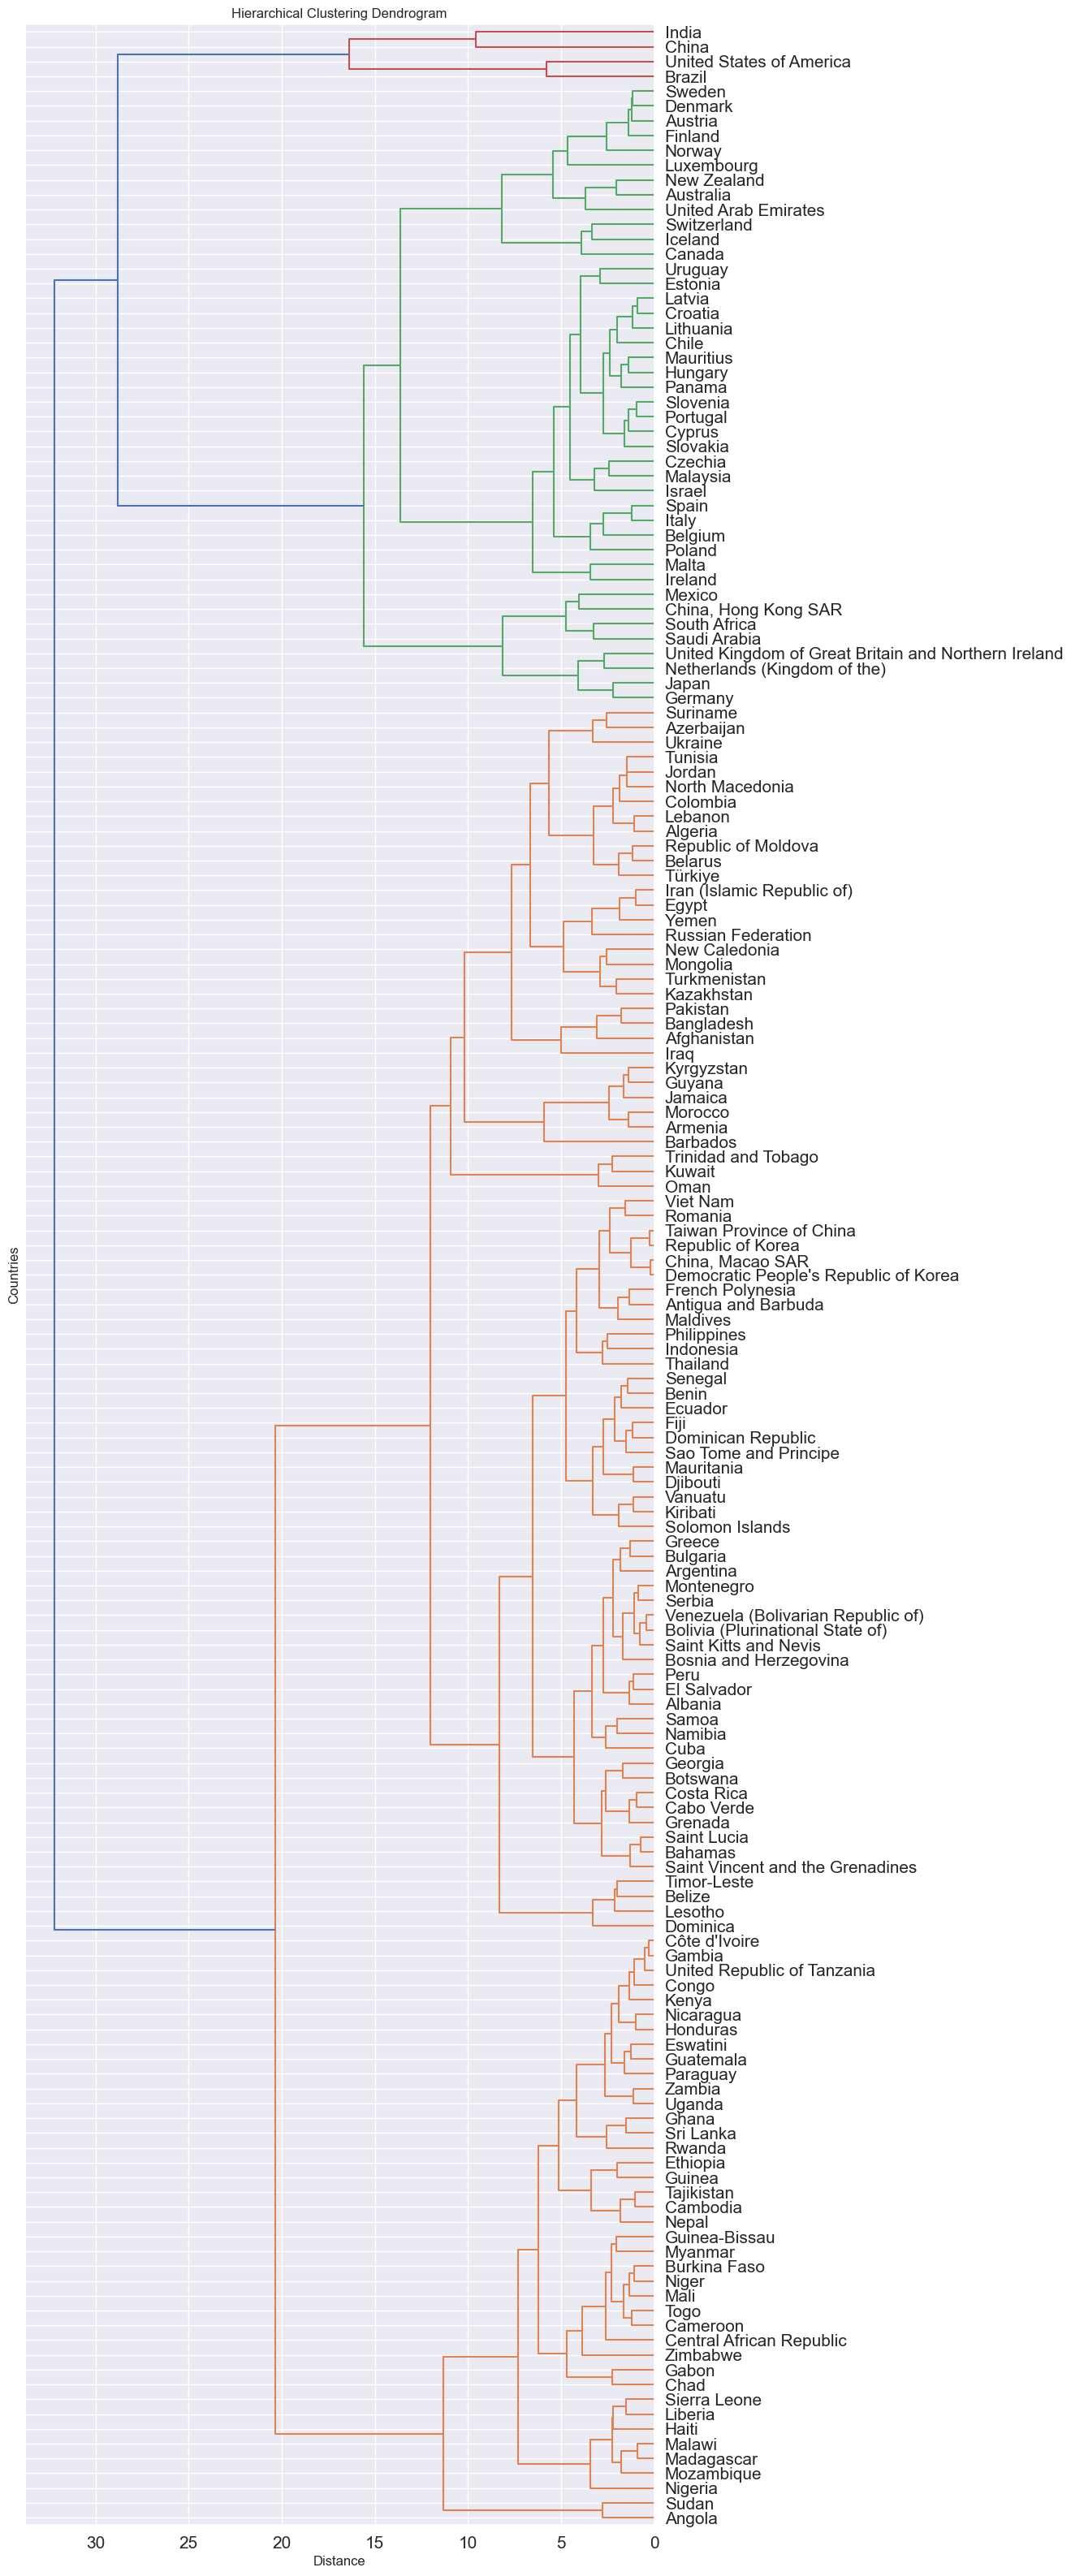

In [49]:
fig, ax = plt.subplots(1, 1, figsize=(10,40))

_ = dendrogram(Z, ax=ax, labels=countries, orientation = "left")

plt.title("Hierarchical Clustering Dendrogram")
ax.set_xlabel("Distance")
ax.set_ylabel("Countries")
ax.tick_params(axis='x', which='major', labelsize=15)
ax.tick_params(axis='y', which='major', labelsize=15)

On distingue 4 groupes de pays : 
- les pays en rouge,
- les pays en vert,
- deux groupes de pays en orange

On va donc utiliser ce nombre de clusters pour notre k-means.

#### K-means ####

In [50]:
k=4

In [51]:
clusters = fcluster(Z, k, criterion='maxclust')
clusters

array([2, 2, 2, 2, 1, 2, 2, 3, 3, 2, 2, 2, 2, 2, 4, 2, 2, 2, 1, 1, 3, 2,
       1, 1, 1, 3, 4, 2, 1, 2, 2, 3, 2, 2, 3, 2, 2, 2, 2, 2, 2, 3, 2, 3,
       2, 2, 2, 1, 1, 3, 2, 1, 2, 2, 2, 1, 1, 2, 1, 1, 3, 3, 3, 3, 4, 2,
       2, 2, 3, 3, 3, 1, 2, 2, 3, 2, 2, 1, 1, 2, 2, 2, 3, 2, 2, 1, 3, 2,
       1, 1, 3, 2, 1, 3, 2, 3, 3, 2, 2, 1, 2, 2, 1, 3, 2, 2, 2, 3, 1, 1,
       1, 3, 2, 3, 3, 1, 2, 2, 3, 3, 1, 2, 1, 2, 1, 2, 2, 2, 2, 2, 3, 2,
       1, 3, 3, 3, 3, 2, 1, 1, 3, 3, 2, 2, 1, 2, 1, 2, 2, 2, 2, 3, 1, 3,
       2, 4, 1, 3, 2, 2, 1, 2, 2, 1, 3, 3, 2, 2, 1], dtype=int32)

In [52]:
crosstab = pd.crosstab(region, clusters, dropna=False)
crosstab.rename_axis(columns="cluster", inplace=True)
crosstab

cluster,1,2,3,4
Region,,,,
AME,5,23,5,2
AP,4,21,5,2
ECA,1,16,1,0
MENA,0,11,3,0
SSA,30,9,2,0
WE/EU,0,3,26,0


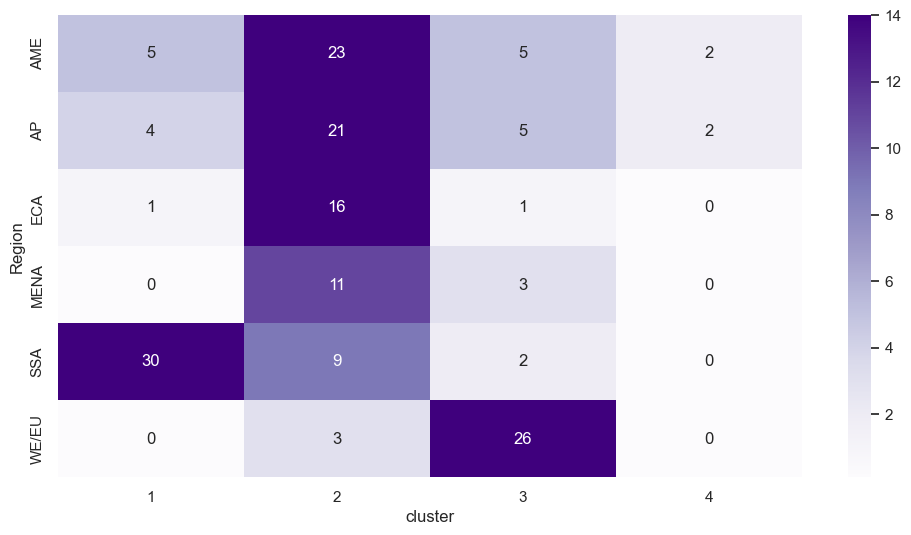

In [53]:
fig, ax = plt.subplots(1,1, figsize=(12,6))
ax = sns.heatmap(crosstab, vmin=0.1, vmax=14, annot=True, cmap="Purples")

In [54]:
df = pd.DataFrame({"Country" : countries, "Region" : region, "Cluster" : clusters})
df.head(20)

,Country,Region,Cluster
0,Armenia,ECA,2
1,Afghanistan,AP,2
2,Albania,ECA,2
3,Algeria,MENA,2
4,Angola,SSA,1
5,Antigua and Barbuda,AME,2
6,Argentina,AME,2
7,Australia,AP,3
8,Austria,WE/EU,3
9,Bahamas,AME,2


In [55]:
intertia_list = [ ]

# Notre liste de nombres de clusters : 
k_list = range(1, 5)

# Pour chaque nombre de clusters : 
for k in k_list : 
    
    # On instancie un k-means pour k clusters
    kmeans = KMeans(n_clusters=k)
    
    # On entraine
    kmeans.fit(X)
    
    # On enregistre l'inertie obtenue : 
    intertia_list.append(kmeans.inertia_)

In [56]:
kmeans.labels_

array([0, 0, 0, 0, 0, 2, 2, 1, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 2, 0, 0, 0, 2, 0, 2, 0, 0, 1, 0, 0, 0, 0, 2, 0, 2, 0, 1,
       2, 0, 0, 0, 0, 1, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 3, 0, 0,
       2, 0, 3, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 2, 0,
       0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 3, 0, 2, 2, 0, 0, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0,
       0, 2, 1, 0, 2, 0, 0, 0, 1, 3, 0, 0, 0, 0, 0, 2, 2, 0, 0, 1, 0, 1,
       0, 0, 0, 2, 0, 0, 0, 0, 2, 0, 1, 3, 0, 0, 0], dtype=int32)

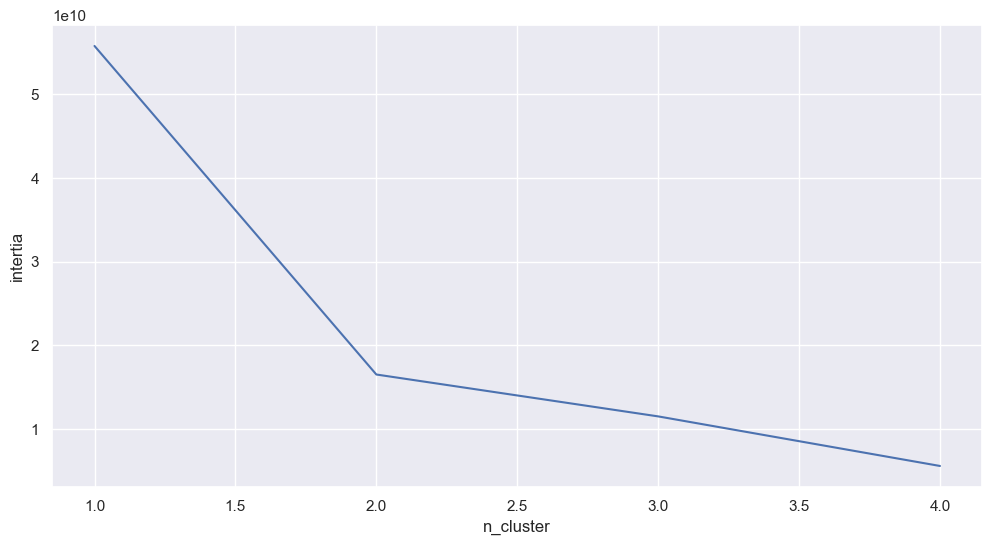

In [57]:
fig, ax = plt.subplots(1,1,figsize=(12,6))

ax.set_ylabel("intertia")
ax.set_xlabel("n_cluster")

ax = plt.plot(k_list, intertia_list)

**Le coude se situe autour de 2 clusters.**

On va cependant retenir 4 clusters aux vues du dendrogramme et de l'analyse des différents groupes de pays.

In [58]:
poulet_exp["Cluster"] = clusters

poulet_exp.groupby("Cluster")[indicators].mean()

C:\Users\capel\AppData\Local\Temp\ipykernel_19260\4291586212.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  poulet_exp["Cluster"] = clusters


,Production,Importations,Exportations,Domestic supply,Population,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,GES per capita,Renewable energy consumption,Infrastructures,Tariffs
Cluster,,,,,,,,,,,,,,,
1,99.200000,27.400000,15.239595,124.575000,25.196250,29.311486,-0.742757,37.131439,4.338331,7.541073,1804.722297,2.165459,71.087635,2.212617,0.295529
2,398.261524,48.795181,55.502766,395.795181,24.700361,40.199987,-0.130204,48.897860,2.896750,3.419982,7942.201269,6.469040,19.518569,2.528704,0.257850
3,630.571429,214.047619,156.023810,652.714286,21.771905,63.810173,0.671174,73.550589,3.571676,2.022055,35565.755902,10.861314,23.061694,3.418255,0.142907
4,14474.000000,144.500000,2123.750000,12517.500000,823.152500,48.250000,-0.316518,55.255268,4.296250,3.055481,7884.142857,5.909911,29.668750,3.038333,0.150125


**Cluster 4** : pays avec une grande population, production importante de poulet, exportations importantes de poulet => pas besoin de poulets.

**Cluster 3** : pays développés, corruption faible, stabilité politique élevée, gouvernements efficaces, haut PIB / habn etc. et surtout, ce sont les pays qui importent le plus de poulets, avec des droits de douane faibles.

**Cluster 2** : pays en voie de développement, corruption elevée, stabilité politique faible, etc.

**Cluster 1** : reste du monde

Il faudrait voir si on peut encore plus réduire le nombre de pays du Cluster 3, le plus propice à l'importation de nos poulets.

### Export du cluster 3 dans un fichier séparé pour analyse complémentaire ###

In [59]:
df_cluster_3 = df[df["Cluster"] == 3].copy()

In [60]:
df_cluster_3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 42 entries, 7 to 165
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Country  42 non-null     object
 1   Region   42 non-null     object
 2   Cluster  42 non-null     int32 
dtypes: int32(1), object(2)
memory usage: 1.1+ KB


In [61]:
df_cluster_3.head()

,Country,Region,Cluster
7,Australia,AP,3
8,Austria,WE/EU,3
20,Canada,AME,3
25,Chile,AME,3
31,Cyprus,WE/EU,3


In [62]:
poulet_dev = df_cluster_3.merge(poulet_final, on="Country", how="left")


In [63]:
poulet_dev.head()

,Country,Region_x,Cluster,Produit,Year,Domestic supply,Exportations,Importations,Production,Population,...,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,Infrastructures,GES per capita,Renewable energy consumption,Tariffs
0,Australia,AP,3,Viande de Volailles,2017,1171.0,42.0,16.0,1269.0,24.58,...,77.0,0.78,83.31,2.29,1.95,54118.0,3.97,24.92,9.9,0.00
1,Austria,WE/EU,3,Viande de Volailles,2017,173.0,78.0,110.0,148.0,8.82,...,75.0,0.93,82.72,2.27,2.08,47164.0,4.18,9.65,34.0,0.00
2,Canada,AME,3,Viande de Volailles,2017,1433.0,163.0,182.0,1417.0,36.73,...,82.0,1.02,89.27,3.03,1.60,45130.0,3.75,21.51,22.8,1.19
3,Chile,AME,3,Viande de Volailles,2017,672.0,115.0,155.0,712.0,18.47,...,67.0,0.59,70.05,1.36,2.18,14880.0,3.21,6.71,24.1,0.00
4,Cyprus,WE/EU,3,Viande de Volailles,2017,38.0,1.0,14.0,25.0,1.18,...,57.0,0.67,73.01,5.75,0.53,26247.0,2.89,7.20,10.9,0.00


In [64]:
poulet_dev.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Country                       42 non-null     object 
 1   Region_x                      42 non-null     object 
 2   Cluster                       42 non-null     int32  
 3   Produit                       42 non-null     object 
 4   Year                          42 non-null     int64  
 5   Domestic supply               42 non-null     float64
 6   Exportations                  42 non-null     float64
 7   Importations                  42 non-null     float64
 8   Production                    42 non-null     float64
 9   Population                    42 non-null     float64
 10  Region_y                      42 non-null     object 
 11  CPI Score                     42 non-null     float64
 12  Political Stability           42 non-null     float64
 13  Governm

In [65]:
poulet_dev = poulet_dev.rename(columns={"Region_x": "Region"})

In [66]:
poulet_dev = poulet_dev.drop(columns=["Region_y"])

In [67]:
poulet_dev.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Country                       42 non-null     object 
 1   Region                        42 non-null     object 
 2   Cluster                       42 non-null     int32  
 3   Produit                       42 non-null     object 
 4   Year                          42 non-null     int64  
 5   Domestic supply               42 non-null     float64
 6   Exportations                  42 non-null     float64
 7   Importations                  42 non-null     float64
 8   Production                    42 non-null     float64
 9   Population                    42 non-null     float64
 10  CPI Score                     42 non-null     float64
 11  Political Stability           42 non-null     float64
 12  Government Effectiveness      42 non-null     float64
 13  Growth 

In [68]:
poulet_dev.to_csv(
    "C:/Users/capel/Desktop/Data Analyst/Projet 10/poulet_dev.csv",
    index=False,
    encoding="utf-8-sig"
)

J'exporte le fichier afin de réduire encore le nombre de pays où exporter du poulet.

Le nouveau fichier créé s'appelle **poulet_dev**.csv.